In [1]:
import requests
import pandas as pd
import numpy as np
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt
retry_strategy = Retry(
    total=5,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=retry_strategy))
url="https://raw.githubusercontent.com/hudl/open-data/master/data/competitions.json"
response=session.get(url,timeout=30)
print(response.status_code)

200


In [2]:
print(type(response.text))
print(response.text[:200])

<class 'str'>
[ {
  "competition_id" : 9,
  "season_id" : 281,
  "country_name" : "Germany",
  "competition_name" : "1. Bundesliga",
  "competition_gender" : "male",
  "competition_youth" : false,
  "competition_in


In [3]:
competitions=response.json()
print(type(competitions))
print(len(competitions))
print(competitions[0])

<class 'list'>
80
{'competition_id': 9, 'season_id': 281, 'country_name': 'Germany', 'competition_name': '1. Bundesliga', 'competition_gender': 'male', 'competition_youth': False, 'competition_international': False, 'season_name': '2023/2024', 'match_updated': '2024-09-28T20:46:38.893391', 'match_updated_360': '2025-11-15T23:17:41.827093', 'match_available_360': '2025-11-15T23:17:41.827093', 'match_available': '2024-09-28T20:46:38.893391'}


In [4]:
for competition in competitions[:10]:
    print(competition["competition_name"],"-",competition["season_name"])

1. Bundesliga - 2023/2024
1. Bundesliga - 2015/2016
African Cup of Nations - 2023
Champions League - 2018/2019
Champions League - 2017/2018
Champions League - 2016/2017
Champions League - 2015/2016
Champions League - 2014/2015
Champions League - 2013/2014
Champions League - 2012/2013


In [5]:
unique_competitions=set()
for competition in competitions:
    unique_competitions.add(competition["competition_name"])
print("Unique competitions:",len(unique_competitions))
print(sorted(unique_competitions))

Unique competitions: 24
['1. Bundesliga', 'African Cup of Nations', 'Champions League', 'Copa America', 'Copa del Rey', "FA Women's Super League", 'FIFA U20 World Cup', 'FIFA World Cup', 'Frauen Bundesliga', 'Indian Super league', 'La Liga', 'Liga F', 'Liga Profesional', 'Ligue 1', 'Major League Soccer', 'NWSL', 'North American League', 'Premier League', 'Serie A', 'Serie A Women', 'UEFA Euro', 'UEFA Europa League', "UEFA Women's Euro", "Women's World Cup"]


In [6]:
for competition in competitions:
    if competition["competition_name"]=="Premier League":
         print(
            competition["season_name"],
            "| Competition ID:", competition["competition_id"],
            "| Season ID:", competition["season_id"]
        )

2015/2016 | Competition ID: 2 | Season ID: 27
2003/2004 | Competition ID: 2 | Season ID: 44


In [7]:
matches_url="https://raw.githubusercontent.com/hudl/open-data/master/data/matches/2/27.json"
matches_response=session.get(matches_url,timeout=30)
print(matches_response.status_code)

200


In [8]:
matches=matches_response.json()
print(type(matches))
print("Number of matches:",len(matches))
print(matches[0].keys())

<class 'list'>
Number of matches: 380
dict_keys(['match_id', 'match_date', 'kick_off', 'competition', 'season', 'home_team', 'away_team', 'home_score', 'away_score', 'match_status', 'match_status_360', 'last_updated', 'last_updated_360', 'metadata', 'match_week', 'competition_stage', 'stadium', 'referee'])


In [9]:
print(matches[0]["match_date"])
print(matches[0]["home_team"]["home_team_name"])
print(matches[0]["away_team"]["away_team_name"])
print(matches[0]["match_id"])

2015-09-19
Chelsea
Arsenal
3754217


In [10]:
match_id=matches[0]["match_id"]
events_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"
events_response=session.get(events_url,timeout=30)
print(events_response.status_code)


200


In [11]:
events=events_response.json()
print(type(events))
print("Number of events:",len(events))
print(events[0].keys())

<class 'list'>
Number of events: 3732
dict_keys(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'duration', 'tactics'])


In [12]:
event_types=set()
for event in events:
    event_types.add(event["type"]["name"])
print(sorted(event_types))

['Bad Behaviour', 'Ball Receipt*', 'Ball Recovery', 'Block', 'Carry', 'Clearance', 'Dispossessed', 'Dribble', 'Dribbled Past', 'Duel', 'Error', 'Foul Committed', 'Foul Won', 'Goal Keeper', 'Half End', 'Half Start', 'Injury Stoppage', 'Interception', 'Miscontrol', 'Own Goal Against', 'Own Goal For', 'Pass', 'Player Off', 'Player On', 'Pressure', 'Referee Ball-Drop', 'Shield', 'Shot', 'Starting XI', 'Substitution', 'Tactical Shift']


In [13]:
shots=[]
for event in events:
    if event["type"]["name"]=="Shot":
        shots.append(event)
print("Number of shots:",len(shots))
print(shots[0].keys())


Number of shots: 33
dict_keys(['id', 'index', 'period', 'timestamp', 'minute', 'second', 'type', 'possession', 'possession_team', 'play_pattern', 'team', 'player', 'position', 'location', 'duration', 'related_events', 'shot'])


In [14]:
print(shots[0]["shot"].keys())


dict_keys(['statsbomb_xg', 'end_location', 'first_time', 'technique', 'body_part', 'type', 'outcome', 'freeze_frame'])


In [15]:
shot=shots[0]
print("Player:",shot["player"]["name"])
print("Location:",shot["location"])
print("StatsBomb xG:",shot["shot"]["statsbomb_xg"])
print("Outcome:",shot["shot"]["outcome"]["name"])

Player: Aaron Ramsey
Location: [94.5, 42.9]
StatsBomb xG: 0.0388317
Outcome: Blocked


In [16]:
goal=shot["shot"]["outcome"]["name"]=="Goal"
print("Goal label:",goal)

Goal label: False


In [17]:
shot_row={
    "x":shot["location"][0],
    "y":shot["location"][1],
    "body_part":shot["shot"]["body_part"]["name"],
    "shot_type":shot["shot"]["type"]["name"],
    "goal":shot["shot"]["outcome"]["name"]=="Goal"
}
print(shot_row)

{'x': 94.5, 'y': 42.9, 'body_part': 'Left Foot', 'shot_type': 'Open Play', 'goal': False}


In [18]:
shot_rows=[]
for event in events:
    if event["type"]["name"]=="Shot":
        shot_rows.append({
            "x":event["location"][0],
            "y":event["location"][1],
            "body_part":event["shot"]["body_part"]["name"],
            "shot_type":event["shot"]["type"]["name"],
            "goal":event["shot"]["outcome"]["name"]=="Goal"

        })
print("Total shot rows:",len(shot_rows))
print(shot_rows[0])

Total shot rows: 33
{'x': 94.5, 'y': 42.9, 'body_part': 'Left Foot', 'shot_type': 'Open Play', 'goal': False}


In [19]:

shots_df=pd.DataFrame(shot_rows)
print(shots_df.shape)
print(shots_df.head())

(33, 5)
       x     y   body_part  shot_type   goal
0   94.5  42.9   Left Foot  Open Play  False
1   93.5  48.4  Right Foot  Open Play  False
2   89.8  22.3  Right Foot  Open Play  False
3   98.2  26.0  Right Foot  Open Play  False
4  105.7  24.2  Right Foot  Open Play  False


In [20]:
total_shots=0
for match in matches[:10]:
    match_id=match["match_id"]
    events_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"

    response=session.get(events_url,timeout=30)
    if response.status_code==200:
        match_events=response.json()
        for event in match_events:
            if event["type"]["name"]=="Shot":
                total_shots+=1
print("Shots across 10 matches:",total_shots)
    


Shots across 10 matches: 260


In [ ]:
dataset_rows=[]
failed_matches=[]
for match in matches:
    match_id=match["match_id"]
    event_url=f"https://raw.githubusercontent.com/hudl/open-data/master/data/events/{match_id}.json"
    response=session.get(event_url,timeout=30)


    if response.status_code==200:
        match_events=response.json()

        for event in match_events:
            if event["type"]["name"]=="Shot":
                dataset_rows.append({
                    "match_id":match_id,
                    "x":event["location"][0],
                    "y":event["location"][1],
                    "body_part":event["shot"]["body_part"]["name"],
                    "shot_type":event["shot"]["type"]["name"],
                    "goal":event["shot"]["outcome"]["name"]=="Goal"
                })
    else:
        failed_matches.append((match_id,response.status_code))

print("Total matches:",len(matches))
print("Total shots:",len(dataset_rows))
print("Total goals:",sum(row["goal"] for row in dataset_rows))
print("Failed matches:",len(failed_matches))


In [22]:
shots_df=pd.DataFrame(dataset_rows)

print("Dataset shape:",shots_df.shape)
print("\nMissing values:")
print(shots_df.isna().sum())


Dataset shape: (9908, 6)

Missing values:
match_id     0
x            0
y            0
body_part    0
shot_type    0
goal         0
dtype: int64


In [23]:
print(shots_df["goal"].value_counts())
print(shots_df["goal"].value_counts(normalize=True)*100) 


goal
False    8920
True      988
Name: count, dtype: int64
goal
False    90.02826
True      9.97174
Name: proportion, dtype: float64


In [24]:
shots_df["distance_to_goal"]=np.sqrt((shots_df["x"]-120)**2+(shots_df["y"]-40)**2)
print(shots_df["distance_to_goal"][:5])

0    25.664372
1    27.799460
2    35.004714
3    25.908300
4    21.310326
Name: distance_to_goal, dtype: float64


In [25]:
shots_df["shot_angle"] = np.degrees(
    np.abs(
        np.arctan2(44 - shots_df["y"], 120 - shots_df["x"])
        - np.arctan2(36 - shots_df["y"], 120 - shots_df["x"])
    )
)
print(shots_df["shot_angle"][:5])

0    17.611035
1    15.648789
2    11.297814
3    14.904419
4    14.633756
Name: shot_angle, dtype: float64


In [26]:
print(shots_df[["distance_to_goal","shot_angle"]].describe())

       distance_to_goal   shot_angle
count       9908.000000  9908.000000
mean          19.071931    25.385163
std            8.291229    15.726347
min            0.921954     0.060911
25%           12.126417    15.305260
50%           18.791620    19.546465
75%           25.339840    30.929350
max           86.137100   159.713824


In [27]:
print(shots_df.sort_values("shot_angle",ascending=False).head())

      match_id      x     y   body_part  shot_type  goal  distance_to_goal  \
3733   3754276  119.3  40.6  Right Foot  Open Play  True          0.921954   
2514   3754167  119.2  41.9  Right Foot  Open Play  True          2.061553   
2767   3754211  118.9  40.3  Right Foot  Open Play  True          1.140175   
3215   3754230  119.3  37.5  Right Foot  Open Play  True          2.596151   
2007   3754112  118.8  41.3       Other  Open Play  True          1.769181   

      shot_angle  
3733  159.713824  
2514  151.423716  
2767  149.093597  
3215  148.836481  
2007  143.279979  


In [28]:
print(shots_df.groupby("goal")[["distance_to_goal","shot_angle"]].mean())

       distance_to_goal  shot_angle
goal                               
False         19.727491   23.946326
True          13.153312   38.375474


In [29]:
print(shots_df["body_part"].value_counts())
print(shots_df["shot_type"].value_counts())


body_part
Right Foot    5367
Left Foot     2916
Head          1608
Other           17
Name: count, dtype: int64
shot_type
Open Play    9415
Free Kick     401
Penalty        91
Corner          1
Name: count, dtype: int64


In [30]:
shots_df.to_csv("shots_2015_16.csv",index=False)


In [31]:
X=shots_df[["distance_to_goal","shot_angle","body_part","shot_type"]]
y=shots_df["goal"]

print("X shape:",X.shape)
print("y shape:",y.shape)


X shape: (9908, 4)
y shape: (9908,)


In [32]:
from sklearn.model_selection import GroupShuffleSplit
group_split=GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx,test_idx=next(
    group_split.split(X,y,groups=shots_df["match_id"])
)

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
numerical_features=["distance_to_goal","shot_angle"]
categorical_features=["body_part","shot_type"]
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

In [34]:
X_train=X.iloc[train_idx]
X_test=X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

X_train_prepared=preprocessor.fit_transform(X_train)
X_test_prepared=preprocessor.transform(X_test)

print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Training shape: (7882, 10)
Testing shape: (2026, 10)


In [35]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000,random_state=42)
model.fit(X_train_prepared,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [36]:
y_pred_proba=model.predict_proba(X_test_prepared)[:,1]
print(y_pred_proba[:10])

[0.09446571 0.127357   0.19023791 0.31255178 0.07449101 0.06023945
 0.06532907 0.08424094 0.07728542 0.19394584]


In [37]:
from sklearn.metrics import roc_auc_score,brier_score_loss,log_loss
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
print("Brier Score:", brier_score_loss(y_test, y_pred_proba))
print("Log Loss:", log_loss(y_test, y_pred_proba))

ROC-AUC: 0.7591347450335802
Brier Score: 0.08062557298233274
Log Loss: 0.2852288909432482


In [38]:
baseline_prob=y_train.mean()
baseline_predictions=np.full(
    len(y_test),
    baseline_prob
)
print("Baseline probability:", baseline_prob)
print("Baseline Brier Score:",
      brier_score_loss(y_test, baseline_predictions))

print("Baseline Log Loss:",
      log_loss(y_test, baseline_predictions))

Baseline probability: 0.09807155544278102
Baseline Brier Score: 0.09492367221776811
Baseline Log Loss: 0.3386841247615682


In [39]:
brier_skill_score=1-(
    brier_score_loss(y_test,y_pred_proba)/
    brier_score_loss(y_test,baseline_predictions)
)
print(brier_skill_score)


0.15062732932027267


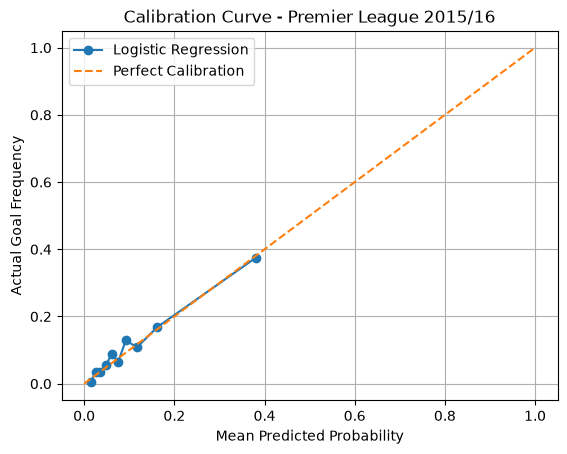

In [40]:
from sklearn.calibration import calibration_curve
prob_true,prob_pred=calibration_curve(
    y_test,
    y_pred_proba,
    n_bins=10,
    strategy="quantile"
)

plt.plot(prob_pred,prob_true,marker="o",label="Logistic Regression")
plt.plot([0,1],[0,1],linestyle="--",label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Goal Frequency")
plt.title("Calibration Curve - Premier League 2015/16")

plt.legend()
plt.grid()
plt.show()

In [41]:
calibration_result=pd.DataFrame({
    "prediction_probabilty":prob_pred,
    "actual_goal_frequency":prob_true
})
print(calibration_result.round(4))

   prediction_probabilty  actual_goal_frequency
0                 0.0143                 0.0049
1                 0.0253                 0.0345
2                 0.0362                 0.0347
3                 0.0483                 0.0542
4                 0.0609                 0.0891
5                 0.0751                 0.0640
6                 0.0923                 0.1287
7                 0.1174                 0.1084
8                 0.1619                 0.1683
9                 0.3801                 0.3744


In [42]:
for shot_event in shots[:5]:
    print(
        "First time:",shot_event["shot"].get("first_time"),
        "Technique:",shot_event["shot"]["technique"]["name"]
    )

First time: True Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal
First time: None Technique: Normal
